In [1]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

In [2]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

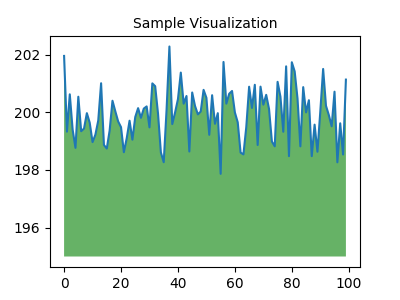

In [3]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

In [4]:

import pandas as pd

# Read all four sheets from the Excel workbook
doctor = pd.read_excel("pharma_sales_dataset.xlsx", sheet_name="doctor_data")

sales = pd.read_excel("pharma_sales_dataset.xlsx", sheet_name="sales_data")

rep = pd.read_excel("pharma_sales_dataset.xlsx", sheet_name="rep_data")

territory = pd.read_excel("pharma_sales_dataset.xlsx", sheet_name="territory_data")

# Display the first five rows
doctor.head()


,Doctor_ID,Region,Specialization
0,D001,North America,Cardiologist
1,D002,North America,Neurologist
2,D003,South Asia,General Physician
3,D004,South Asia,Orthopedic
4,D005,Europe,Cardiologist


In [5]:
doctor.info()
sales.info()
rep.info()
territory.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Doctor_ID       100 non-null    str  
 1   Region          100 non-null    str  
 2   Specialization  100 non-null    str  
dtypes: str(3)
memory usage: 2.5 KB
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   10000 non-null  datetime64[us]
 1   year                   10000 non-null  int64         
 2   month                  10000 non-null  int64         
 3   day                    10000 non-null  int64         
 4   region                 10000 non-null  str           
 5   country                10000 non-null  str           
 6   category               10000 non-null  str           
 7   medicine               1

In [6]:
sales['date'] = pd.to_datetime(sales['date'])

In [7]:
sales['date'] = pd.to_datetime(sales['date'], dayfirst=True)

In [8]:
sales['date'].head()

0   2021-03-29
1   2021-03-18
2   2021-03-02
3   2021-04-03
4   2025-01-09
Name: date, dtype: datetime64[us]

In [9]:
doctor.duplicated().sum()
sales.duplicated().sum()
rep.duplicated().sum()
territory.duplicated().sum()

np.int64(0)

In [10]:
sales['calculated_revenue'] = sales['units_sold'] * sales['unit_price']

In [11]:
(sales['Revenue'] - sales['calculated_revenue']).abs().sum()

np.float64(0.0)

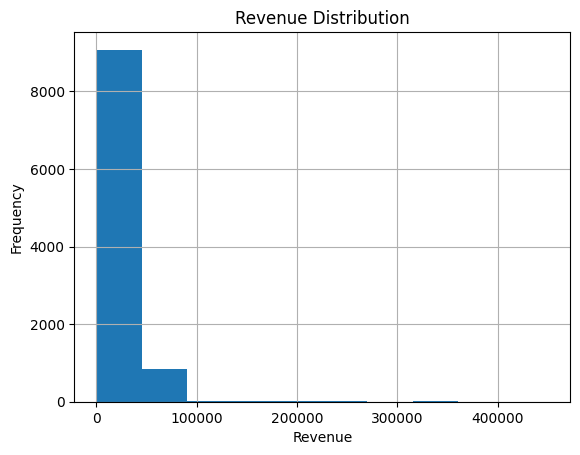

In [12]:
import matplotlib.pyplot as plt

sales['Revenue'].hist()

plt.title("Revenue Distribution")
plt.xlabel("Revenue")        # X-axis label
plt.ylabel("Frequency")      # Y-axis label

plt.show()

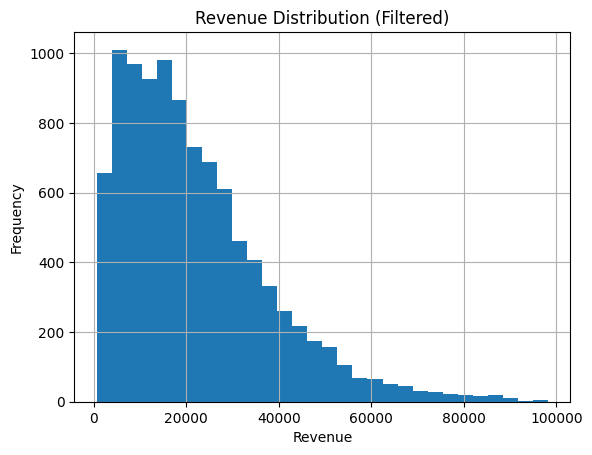

In [13]:
sales[sales['Revenue'] < 100000]['Revenue'].hist(bins=30)

plt.title("Revenue Distribution (Filtered)")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.show()

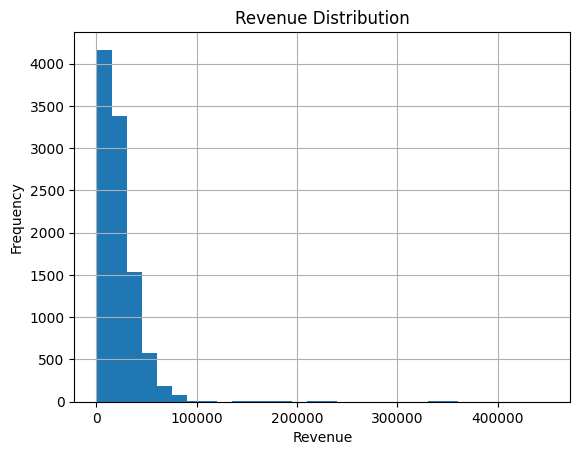

In [14]:
sales['Revenue'].hist(bins=30)

plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.show()

In [15]:
sales = pd.read_excel("pharma_sales_dataset.xlsx", sheet_name="sales_data")

sales.columns

Index(['date', 'year', 'month', 'day', 'region', 'country', 'category',
       'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level',
       'expiry_days_remaining', 'covid_flag', 'Revenue', 'DOCTOR_ID'],
      dtype='str')

In [16]:
top_doctors = sales.groupby('DOCTOR_ID')['Revenue'].sum().sort_values(ascending=False).head(10)
top_doctors

DOCTOR_ID
D012    3150298.61
D087    3135591.62
D054    3119299.05
D004    3108062.74
D034    3068385.13
D027    2993990.94
D048    2982268.60
D014    2944573.11
D053    2822599.55
D016    2818162.64
Name: Revenue, dtype: float64

In [17]:
merged = pd.merge(sales, doctor, left_on='DOCTOR_ID', right_on='Doctor_ID', how='left')

In [18]:
merged.drop(columns=['Doctor_ID'], inplace=True)

In [19]:
merged.groupby(['DOCTOR_ID','Region','Specialization'])['Revenue'] \
    .sum().sort_values(ascending=False).head(10)

DOCTOR_ID  Region         Specialization   
D012       East Asia      Orthopedic           3150298.61
D087       Africa         General Physician    3135591.62
D054       Europe         Neurologist          3119299.05
D004       South Asia     Orthopedic           3108062.74
D034       North America  Neurologist          3068385.13
D027       East Asia      General Physician    2993990.94
D048       Oceania        Orthopedic           2982268.60
D014       South America  Neurologist          2944573.11
D053       Europe         Cardiologist         2822599.55
D016       Oceania        Orthopedic           2818162.64
Name: Revenue, dtype: float64

In [20]:
region_revenue = merged.groupby('Region')['Revenue'] \
    .sum().sort_values(ascending=False)

region_revenue

Region
North America    32285235.91
South Asia       31054695.49
Europe           29089143.52
East Asia        28988167.57
Oceania          28662632.37
South America    28503413.28
Africa           28169661.29
Middle East      25483677.08
Name: Revenue, dtype: float64

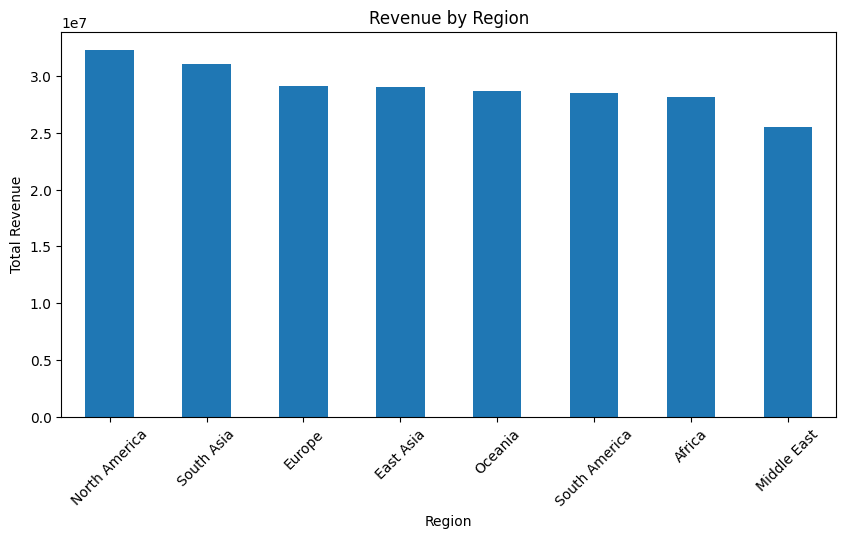

In [21]:
region_revenue.plot(kind='bar', figsize=(10,5))
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [22]:
medicine_revenue = merged.groupby('medicine')['Revenue'] \
    .sum().sort_values(ascending=False)

medicine_revenue.head(10)

medicine
Paracetamol     25058087.62
Metformin       24595848.06
Cetirizine      23865212.29
Ibuprofen       23674928.51
Amlodipine      23305543.91
Multivitamin    22728104.01
Cough Syrup     22452995.01
Amoxicillin     22307103.43
Vitamin C       22243771.13
Azithromycin    22005032.54
Name: Revenue, dtype: float64

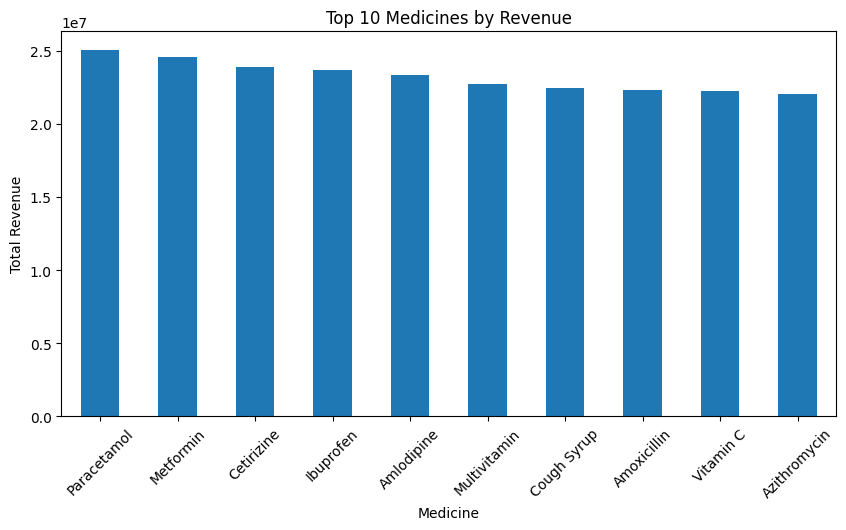

In [23]:
medicine_revenue.head(10).plot(kind='bar', figsize=(10,5))
plt.title("Top 10 Medicines by Revenue")
plt.xlabel("Medicine")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [24]:
merged_full = pd.merge(merged, rep, left_on='Region', right_on='Region', how='left')

In [25]:
rep_performance = merged_full.groupby('Rep_ID')['Revenue'] \
    .sum().sort_values(ascending=False)

rep_performance

Rep_ID
R001    32285235.91
R002    32285235.91
R003    31054695.49
R004    31054695.49
R005    29089143.52
R006    29089143.52
R011    28988167.57
R012    28988167.57
R015    28662632.37
R014    28503413.28
R013    28503413.28
R007    28169661.29
R008    28169661.29
R010    25483677.08
R009    25483677.08
Name: Revenue, dtype: float64

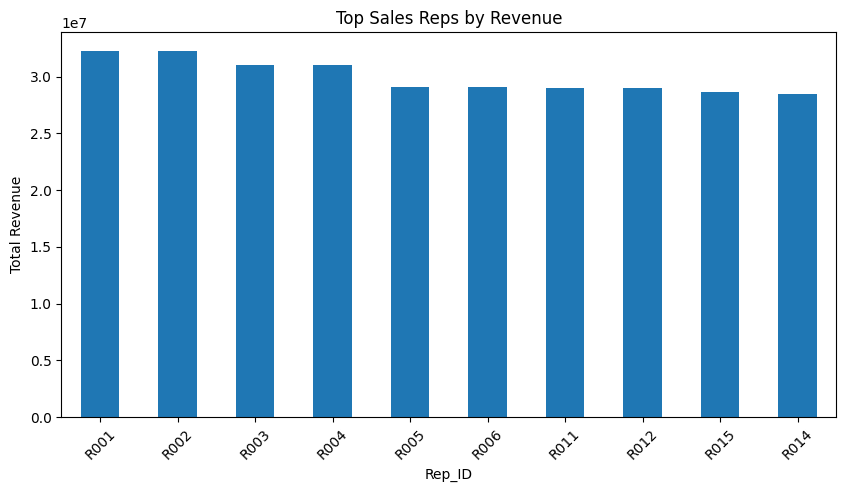

In [26]:
rep_performance.head(10).plot(kind='bar', figsize=(10,5))
plt.title("Top Sales Reps by Revenue")
plt.xlabel("Rep_ID")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [27]:
rep_efficiency = merged_full.groupby('Rep_ID').agg({
    'Revenue': 'sum',
    'Calls_Made': 'sum',
    'Meetings': 'sum'
})

rep_efficiency['Revenue_per_Call'] = rep_efficiency['Revenue'] / rep_efficiency['Calls_Made']
rep_efficiency['Revenue_per_Meeting'] = rep_efficiency['Revenue'] / rep_efficiency['Meetings']

rep_efficiency.sort_values(by='Revenue_per_Meeting', ascending=False).head(10)

,Revenue,Calls_Made,Meetings,Revenue_per_Call,Revenue_per_Meeting
Rep_ID,,,,,
R015,28662632.37,88410,35364,324.201248,810.503121
R005,29089143.52,97040,38816,299.764463,749.411158
R012,28988167.57,104295,41718,277.943982,694.859954
R002,32285235.91,124200,49680,259.945539,649.863847
R009,25483677.08,106875,42750,238.443762,596.109405
R007,28169661.29,120900,48360,232.999680,582.499200
R010,25483677.08,118125,47250,215.734832,539.337081
R011,28988167.57,141105,56442,205.436856,513.592140
R004,31054695.49,151690,60676,204.724738,511.811845


In [28]:
merged.groupby('Specialization')['Revenue'].sum().sort_values(ascending=False)

Specialization
Orthopedic           60961358.62
Cardiologist         57875925.24
Neurologist          57485544.55
General Physician    55913798.10
Name: Revenue, dtype: float64

In [29]:
merged.groupby(['Region','Specialization'])['Revenue'].sum().sort_values(ascending=False).head(10)

Region         Specialization   
South Asia     Orthopedic           16860554.63
North America  Cardiologist         16192659.01
               Neurologist          16092576.90
East Asia      Orthopedic           15583275.93
Oceania        Orthopedic           15174785.26
Africa         General Physician    14826918.49
Europe         Neurologist          14717793.76
               Cardiologist         14371349.76
South America  Neurologist          14352763.14
South Asia     General Physician    14194140.86
Name: Revenue, dtype: float64

In [30]:
sales.groupby('category')['Revenue'].sum().sort_values(ascending=False)

category
Antipyretic    48733016.13
Chronic        47901391.97
Cough_Cold     46318207.30
Vitamin        44971875.14
Antibiotic     44312135.97
Name: Revenue, dtype: float64

In [31]:
sales.groupby('medicine')['Revenue'].sum().sort_values(ascending=False).head(10)

medicine
Paracetamol     25058087.62
Metformin       24595848.06
Cetirizine      23865212.29
Ibuprofen       23674928.51
Amlodipine      23305543.91
Multivitamin    22728104.01
Cough Syrup     22452995.01
Amoxicillin     22307103.43
Vitamin C       22243771.13
Azithromycin    22005032.54
Name: Revenue, dtype: float64

In [32]:
merged.groupby('Region')['Revenue'].mean().sort_values(ascending=False)

Region
Europe           23981.157065
South America    23673.931296
East Asia        23625.238443
North America    23395.098486
Africa           23299.967982
Oceania          22694.087387
Middle East      22652.157404
South Asia       22519.721168
Name: Revenue, dtype: float64

In [33]:
import sqlite3

conn = sqlite3.connect('pharma.db')

In [34]:
sales.to_sql('sales', conn, if_exists='replace', index=False)
doctor.to_sql('doctor', conn, if_exists='replace', index=False)
rep.to_sql('rep', conn, if_exists='replace', index=False)
territory.to_sql('territory', conn, if_exists='replace', index=False)

8

In [35]:
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)

,name
0,sales
1,doctor
2,rep
3,territory


In [36]:
pd.read_sql("SELECT * FROM sales LIMIT 5;", conn)

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag,Revenue,DOCTOR_ID
0,2021-03-29 00:00:00,2021,3,29,North America,USA,Chronic,Amlodipine,26-45,8256,54.49,0,358,1,449869.44,D053
1,2021-03-18 00:00:00,2021,3,18,Middle East,UAE,Chronic,Metformin,13-25,7868,51.90,0,252,1,408349.20,D012
2,2021-03-02 00:00:00,2021,3,2,Africa,Kenya,Vitamin,Multivitamin,46-65,5090,77.32,99,185,1,393558.80,D077
3,2021-04-03 00:00:00,2021,4,3,South America,Argentina,Antipyretic,Paracetamol,0-12,4326,84.27,639,415,1,364552.02,D001
4,2025-01-09 00:00:00,2025,1,9,South America,Argentina,Cough_Cold,Cetirizine,46-65,4544,79.51,405,247,0,361293.44,D093


In [37]:
query = """
SELECT
    s.DOCTOR_ID,
    d.Specialization,
    SUM(s.Revenue) AS total_revenue
FROM sales s
LEFT JOIN doctor d
ON s.DOCTOR_ID = d.DOCTOR_ID
GROUP BY s.DOCTOR_ID, d.Specialization
ORDER BY total_revenue DESC
"""

pd.read_sql(query, conn)

,DOCTOR_ID,Specialization,total_revenue
0,D012,Orthopedic,3150298.61
1,D087,General Physician,3135591.62
2,D054,Neurologist,3119299.05
3,D004,Orthopedic,3108062.74
4,D034,Neurologist,3068385.13
...,...,...,...
95,D009,Cardiologist,1758149.97
96,D010,Neurologist,1742876.36
97,D100,Orthopedic,1728308.11
98,D019,General Physician,1683487.51


In [38]:
query = """
SELECT
    s.DOCTOR_ID,
    d.Specialization,
    SUM(s.Revenue) AS total_revenue,
    RANK() OVER (ORDER BY SUM(s.Revenue) DESC) AS rank
FROM sales s
LEFT JOIN doctor d
ON s.DOCTOR_ID = d.DOCTOR_ID
GROUP BY s.DOCTOR_ID, d.Specialization
"""

pd.read_sql(query, conn)

,DOCTOR_ID,Specialization,total_revenue,rank
0,D012,Orthopedic,3150298.61,1
1,D087,General Physician,3135591.62,2
2,D054,Neurologist,3119299.05,3
3,D004,Orthopedic,3108062.74,4
4,D034,Neurologist,3068385.13,5
...,...,...,...,...
95,D009,Cardiologist,1758149.97,96
96,D010,Neurologist,1742876.36,97
97,D100,Orthopedic,1728308.11,98
98,D019,General Physician,1683487.51,99


In [39]:
query = """
SELECT
    s.DOCTOR_ID,
    d.Specialization,
    SUM(s.Revenue) AS total_revenue,
    ROW_NUMBER() OVER (ORDER BY SUM(s.Revenue) DESC) AS row_num
FROM sales s
LEFT JOIN doctor d
ON s.DOCTOR_ID = d.DOCTOR_ID
GROUP BY s.DOCTOR_ID, d.Specialization
"""
pd.read_sql(query, conn)

,DOCTOR_ID,Specialization,total_revenue,row_num
0,D012,Orthopedic,3150298.61,1
1,D087,General Physician,3135591.62,2
2,D054,Neurologist,3119299.05,3
3,D004,Orthopedic,3108062.74,4
4,D034,Neurologist,3068385.13,5
...,...,...,...,...
95,D009,Cardiologist,1758149.97,96
96,D010,Neurologist,1742876.36,97
97,D100,Orthopedic,1728308.11,98
98,D019,General Physician,1683487.51,99


In [40]:
query = """
WITH doctor_revenue AS (
    SELECT
        DOCTOR_ID,
        SUM(Revenue) AS total_revenue
    FROM sales
    GROUP BY DOCTOR_ID
)

SELECT *
FROM doctor_revenue
ORDER BY total_revenue DESC
LIMIT 10
"""
pd.read_sql(query, conn)

,DOCTOR_ID,total_revenue
0,D012,3150298.61
1,D087,3135591.62
2,D054,3119299.05
3,D004,3108062.74
4,D034,3068385.13
5,D027,2993990.94
6,D048,2982268.60
7,D014,2944573.11
8,D053,2822599.55
9,D016,2818162.64


In [41]:
query = """
WITH doctor_revenue AS (
    SELECT
        DOCTOR_ID,
        SUM(Revenue) AS total_revenue
    FROM sales
    GROUP BY DOCTOR_ID
)

SELECT
    DOCTOR_ID,
    total_revenue,
    RANK() OVER (ORDER BY total_revenue DESC) AS rank
FROM doctor_revenue
"""
pd.read_sql(query, conn)

,DOCTOR_ID,total_revenue,rank
0,D012,3150298.61,1
1,D087,3135591.62,2
2,D054,3119299.05,3
3,D004,3108062.74,4
4,D034,3068385.13,5
...,...,...,...
95,D009,1758149.97,96
96,D010,1742876.36,97
97,D100,1728308.11,98
98,D019,1683487.51,99


In [42]:
query = """
SELECT *
FROM (
    SELECT
        DOCTOR_ID,
        SUM(Revenue) AS total_revenue,
        NTILE(10) OVER (ORDER BY SUM(Revenue) DESC) AS percentile
    FROM sales
    GROUP BY DOCTOR_ID
)
WHERE percentile = 1
"""
pd.read_sql(query, conn)

,DOCTOR_ID,total_revenue,percentile
0,D012,3150298.61,1
1,D087,3135591.62,1
2,D054,3119299.05,1
3,D004,3108062.74,1
4,D034,3068385.13,1
5,D027,2993990.94,1
6,D048,2982268.60,1
7,D014,2944573.11,1
8,D053,2822599.55,1
9,D016,2818162.64,1


In [43]:
query = """
WITH ranked_docs AS (
    SELECT
        s.Region,
        s.DOCTOR_ID,
        SUM(s.Revenue) AS total_revenue,
        RANK() OVER (
            PARTITION BY s.Region
            ORDER BY SUM(s.Revenue) DESC
        ) AS rank
    FROM sales s
    GROUP BY s.Region, s.DOCTOR_ID
)

SELECT *
FROM ranked_docs
WHERE rank <= 3;
"""

pd.read_sql(query, conn)

,Region,DOCTOR_ID,total_revenue,rank
0,Africa,D054,966088.03,1
1,Africa,D031,930934.86,2
2,Africa,D077,836480.96,3
3,East Asia,D087,573402.96,1
4,East Asia,D034,541470.24,2
5,East Asia,D067,501917.78,3
6,Europe,D022,547749.68,1
7,Europe,D034,547066.44,2
8,Europe,D042,517855.96,3
9,Middle East,D012,1073624.02,1


In [44]:
query = """
SELECT
    Region,
    SUM(Revenue) AS region_revenue,
    ROUND(
        100.0 * SUM(Revenue) /
        (SELECT SUM(Revenue) FROM sales),
        2
    ) AS contribution_percent
FROM sales
GROUP BY Region
ORDER BY contribution_percent DESC;
"""

pd.read_sql(query, conn)

,region,region_revenue,contribution_percent
0,South America,30748027.70,13.24
1,Middle East,30000598.19,12.92
2,Africa,29765336.51,12.82
3,North America,28900022.93,12.44
4,Oceania,28590990.25,12.31
5,South Asia,28418685.10,12.24
6,Europe,28194325.38,12.14
7,East Asia,27618640.45,11.89


In [45]:
query = """
WITH doctor_sales AS (
    SELECT
        DOCTOR_ID,
        SUM(Revenue) AS total_revenue
    FROM sales
    GROUP BY DOCTOR_ID
)

SELECT *
FROM doctor_sales
WHERE total_revenue > (
    SELECT AVG(total_revenue) FROM doctor_sales
);
"""

pd.read_sql(query, conn)

,DOCTOR_ID,total_revenue
0,D001,2752835.12
1,D002,2433363.12
2,D004,3108062.74
3,D008,2422091.04
4,D011,2398716.40
5,D012,3150298.61
6,D014,2944573.11
7,D016,2818162.64
8,D017,2372469.83
9,D023,2450243.67
